# PROJETO DE COLETA DE DADOS
## Preços de imóveis e perfil construtivo por material nas cinco regiões do Brasil

**Autor:** Jedson Correa Leite  
**Data:** 03/11/2026  
**Disciplina:** Introdução à Ciência de Dados

---

## 1. OBJETIVO

Coletar e integrar dados públicos de preços anunciados de imóveis e de características construtivas dos domicílios brasileiros, comparando as cinco Grandes Regiões do Brasil. O foco construtivo será o material predominante nas paredes externas: alvenaria/taipa com revestimento, alvenaria/taipa sem revestimento, madeira apropriada para construção e outros materiais.


## 2. FONTES DE DADOS

| Fonte | URL | Método | Dados coletados |
|---|---|---|---|
| Guru dos Imóveis – Dados Abertos | https://gurudosimoveis.com.br/dados | Download de CSV por cidade via HTTP | Mês, bairro, transação, mediana do preço por m², percentis, anúncios ativos e dias no mercado |
| IBGE – PNAD Contínua, SIDRA tabela 6822 | https://sidra.ibge.gov.br/tabela/6822 | API REST pública (JSON) | Percentual de domicílios por material predominante nas paredes, por Grande Região |

## 3. METODOLOGIA

### 3.1 Coleta
O notebook consulta a página de dados abertos do Guru dos Imóveis, identifica os links CSV das cidades selecionadas nas cinco regiões e baixa os arquivos. Depois consulta a API SIDRA do IBGE para obter a distribuição percentual dos domicílios por material predominante nas paredes, usando o ano de 2025 (último período disponível na tabela consultada na preparação do projeto).

### 3.2 Limpeza
São padronizados os nomes das colunas, os textos das categorias, as cidades e as regiões. As variáveis numéricas são convertidas para tipo numérico; registros sem preço mediano válido são removidos; são mantidas apenas observações de venda e o último mês comum entre as cidades selecionadas. Valores não disponíveis da API do IBGE são tratados como ausentes, sem substituição artificial.

### 3.3 Processamento
Os preços por bairro são resumidos primeiro por cidade (mediana das medianas de bairro). Para cada região, calcula-se a mediana dos indicadores das cidades selecionadas. Cada cidade tem o mesmo peso nessa síntese regional; não se trata de média ponderada pela população ou pelo total de imóveis da região. Os percentuais da PNAD são organizados em formato tabular e integrados por Grande Região. A comparação final é descritiva e exploratória.

## 4. DATASET FINAL

Os totais de registros, colunas, período e tamanho serão preenchidos automaticamente ao executar o notebook, pois dependem dos CSVs efetivamente disponibilizados na data da coleta.

Arquivos previstos:
- `imoveis_bairros.csv`: observações de preço por bairro, cidade e mês.
- `precos_cidades.csv`: resumo de preço por cidade.
- `perfil_construtivo_pnad.csv`: percentuais por região e material.
- `integrado_regional.csv`: preço regional e perfil de materiais em uma linha por região.
- `documentacao_resultados.md`: documentação preenchida com os resultados da execução.

## 5. ANÁLISE EXPLORATÓRIA

### 5.1 Estatísticas descritivas
Serão apresentados quantidade de bairros e cidades observadas, mediana, média, desvio-padrão, mínimo e máximo dos preços medianos por m², além dos percentuais regionais por material das paredes.

### 5.2 Visualizações
1. Gráfico de barras do preço mediano por m² nas regiões (mediana das cidades selecionadas).
2. Boxplot das medianas de preço por bairro, agrupadas por região.
3. Gráfico de barras agrupadas com o percentual de domicílios por material das paredes.
4. Gráfico exploratório comparando o preço regional e o percentual de domicílios com alvenaria/taipa com revestimento.

## 6. INSIGHTS

Os insights serão redigidos somente após a execução e a conferência dos dados reais. O notebook imprimirá perguntas orientadoras e evitará conclusões causais.

## 7. LIMITAÇÕES

- Os valores do Guru dos Imóveis são medianas de anúncios, não preços efetivamente transacionados.
- A cobertura de cidades é desigual entre regiões; a Região Norte tem menor quantidade de cidades disponíveis na página de dados consultada.
- A base de preços não informa o material de construção de cada imóvel.
- A PNAD apresenta estimativas amostrais regionais; não é uma base de avaliação individual de imóveis.
- As duas fontes têm periodicidades e unidades de observação distintas.
- A mediana regional é calculada a partir das cidades selecionadas, sem ponderação populacional, e não representa necessariamente toda a região.

## 8. PRÓXIMOS PASSOS

- Ampliar a lista de cidades à medida que novos CSVs forem disponibilizados.
- Buscar, em etapa futura, uma base de anúncios individualizados com atributo explícito e verificável de material construtivo, respeitando os termos de uso da fonte.
- Acrescentar variáveis de localização, tipologia e área quando houver dados comparáveis.

## 9. CÓDIGO

Notebook: `notebooks/projeto_coleta_imobiliario_brasil.ipynb`  
Ambiente de execução: Google Colab.  
Repositório GitHub sugerido: `analise-imobiliaria-material-brasil` (substituir pelo endereço criado pelo autor).

## 10. REFERÊNCIAS

- GURU DOS IMÓVEIS. **Dados abertos do mercado imobiliário brasileiro**. Disponível em: https://gurudosimoveis.com.br/dados. Acesso em: 09 nov. 2026.
- IBGE. **Pesquisa Nacional por Amostra de Domicílios Contínua – PNAD Contínua: tabela 6822, Domicílios e Moradores, por material predominante nas paredes**. SIDRA. Disponível em: https://sidra.ibge.gov.br/tabela/6822. Acesso em: 09 nov. 2026.
- IBGE. **Pesquisa Nacional por Amostra de Domicílios Contínua: características gerais dos domicílios e dos moradores**. Disponível em: https://www.ibge.gov.br/estatisticas/sociais/trabalho/17270-pnad-continua.html. Acesso em: 09 nov. 2026.


In [1]:

# ============================================================
# PARTE 1: CONFIGURAÇÃO E IMPORTAÇÕES
# ============================================================
import requests
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pathlib import Path
from datetime import datetime
import unicodedata
import re
import json
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

PASTA_DADOS = Path("dados")
PASTA_GRAFICOS = Path("graficos")
PASTA_DADOS.mkdir(exist_ok=True)
PASTA_GRAFICOS.mkdir(exist_ok=True)

URL_GURU = "https://gurudosimoveis.com.br/dados"
URL_SIDRA = "https://apisidra.ibge.gov.br/values/t/6822/n2/all/v/9784/p/2025/c338/all"

CIDADES = [
    {"slug": "belem-pa.csv", "cidade": "Belém", "uf": "PA", "regiao": "Norte"},
    {"slug": "salvador-ba.csv", "cidade": "Salvador", "uf": "BA", "regiao": "Nordeste"},
    {"slug": "joao-pessoa-pb.csv", "cidade": "João Pessoa", "uf": "PB", "regiao": "Nordeste"},
    {"slug": "recife-pe.csv", "cidade": "Recife", "uf": "PE", "regiao": "Nordeste"},
    {"slug": "fortaleza-ce.csv", "cidade": "Fortaleza", "uf": "CE", "regiao": "Nordeste"},
    {"slug": "goiania-go.csv", "cidade": "Goiânia", "uf": "GO", "regiao": "Centro-Oeste"},
    {"slug": "cuiaba-mt.csv", "cidade": "Cuiabá", "uf": "MT", "regiao": "Centro-Oeste"},
    {"slug": "campo-grande-ms.csv", "cidade": "Campo Grande", "uf": "MS", "regiao": "Centro-Oeste"},
    {"slug": "sao-paulo-sp.csv", "cidade": "São Paulo", "uf": "SP", "regiao": "Sudeste"},
    {"slug": "rio-de-janeiro-rj.csv", "cidade": "Rio de Janeiro", "uf": "RJ", "regiao": "Sudeste"},
    {"slug": "belo-horizonte-mg.csv", "cidade": "Belo Horizonte", "uf": "MG", "regiao": "Sudeste"},
    {"slug": "campinas-sp.csv", "cidade": "Campinas", "uf": "SP", "regiao": "Sudeste"},
    {"slug": "curitiba-pr.csv", "cidade": "Curitiba", "uf": "PR", "regiao": "Sul"},
    {"slug": "florianopolis-sc.csv", "cidade": "Florianópolis", "uf": "SC", "regiao": "Sul"},
    {"slug": "porto-alegre-rs.csv", "cidade": "Porto Alegre", "uf": "RS", "regiao": "Sul"},
]
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

def normalizar_texto(valor):
    """Remove acentos e padroniza texto para comparação."""
    texto = str(valor).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(ch for ch in texto if not unicodedata.combining(ch))
    return re.sub(r"\s+", " ", texto)

session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (compatible; ProjetoAcademicoDados/1.0)"})

print("✅ Ambiente configurado!")
print(f"Data da execução: {datetime.now().strftime('%d/%m/%Y %H:%M')}")
print(f"Cidades previstas: {len(CIDADES)}")


✅ Ambiente configurado!
Data da execução: 10/11/2026 03:08
Cidades previstas: 15


In [2]:

# ============================================================
# PARTE 2: COLETA DE DADOS
# ============================================================

# 2.1 - Guru dos Imóveis: localizar os CSVs por cidade
resposta_pagina = session.get(URL_GURU, timeout=30)
resposta_pagina.raise_for_status()
soup = BeautifulSoup(resposta_pagina.text, "html.parser")

links_csv = {}
for link in soup.find_all("a", href=True):
    href = urljoin(URL_GURU, link["href"])
    nome_arquivo = href.split("?")[0].rstrip("/").split("/")[-1].lower()
    if nome_arquivo.endswith(".csv"):
        links_csv[nome_arquivo] = href

print(f"✅ Links CSV localizados: {len(links_csv)}")

# 2.2 - Baixar arquivos das cidades selecionadas
frames_imoveis = []
cidades_sem_arquivo = []
erros_download = []

for item in CIDADES:
    url_csv = links_csv.get(item["slug"])
    if not url_csv:
        cidades_sem_arquivo.append(item["cidade"])
        continue

    try:
        resposta_csv = session.get(url_csv, timeout=30)
        resposta_csv.raise_for_status()
        df_cidade = pd.read_csv(io.StringIO(resposta_csv.text), comment="#")
        df_cidade.columns = [str(c).strip().lower().replace("\ufeff", "") for c in df_cidade.columns]

        colunas_obrigatorias = {
            "mes", "bairro", "transacao", "mediana_m2",
            "p25_m2", "p75_m2", "anuncios_ativos_media_dia"
        }
        faltantes = colunas_obrigatorias - set(df_cidade.columns)
        if faltantes:
            raise ValueError(f"Colunas não encontradas: {sorted(faltantes)}")

        df_cidade["cidade"] = item["cidade"]
        df_cidade["uf"] = item["uf"]
        df_cidade["regiao"] = item["regiao"]
        frames_imoveis.append(df_cidade)
        print(f"✅ {item['cidade']}: {len(df_cidade)} registros")
    except Exception as erro:
        erros_download.append({"cidade": item["cidade"], "erro": str(erro)})
        print(f"⚠️ Não foi possível coletar {item['cidade']}: {erro}")

if not frames_imoveis:
    raise RuntimeError(
        "Nenhum CSV foi coletado. Verifique a conexão do Colab e os links publicados em "
        "https://gurudosimoveis.com.br/dados."
    )

df_imoveis_bruto = pd.concat(frames_imoveis, ignore_index=True)

regioes_sem_dados = sorted(set(REGIOES) - set(df_imoveis_bruto["regiao"].unique()))
if regioes_sem_dados:
    raise RuntimeError(
        "Não foi possível obter dados de todas as cinco regiões. "
        f"Regiões sem cobertura nesta coleta: {regioes_sem_dados}. "
        "Consulte a página de dados abertos e atualize a lista de cidades."
    )

print(f"\nRegistros brutos: {len(df_imoveis_bruto):,}")
print(f"Cidades coletadas: {df_imoveis_bruto['cidade'].nunique()}")
print("Cidades sem arquivo:", cidades_sem_arquivo if cidades_sem_arquivo else "Nenhuma")

# 2.3 - IBGE / PNAD Contínua: tabela SIDRA 6822
resposta_sidra = session.get(URL_SIDRA, timeout=30)
resposta_sidra.raise_for_status()
dados_sidra = resposta_sidra.json()

if not isinstance(dados_sidra, list) or len(dados_sidra) < 2:
    raise ValueError("A API SIDRA não retornou a estrutura esperada.")

df_pnad_bruto = pd.DataFrame(dados_sidra[1:])
print(f"\n✅ SIDRA: {len(df_pnad_bruto)} registros recebidos.")
print("Colunas retornadas pela API:", df_pnad_bruto.columns.tolist())


✅ Links CSV localizados: 120
✅ Belém: 874 registros
✅ Salvador: 3647 registros
✅ João Pessoa: 1555 registros
✅ Recife: 1868 registros
✅ Fortaleza: 2132 registros
✅ Goiânia: 6660 registros
✅ Cuiabá: 3106 registros
✅ Campo Grande: 3766 registros
✅ São Paulo: 31808 registros
✅ Rio de Janeiro: 3452 registros
✅ Belo Horizonte: 5621 registros
✅ Campinas: 7263 registros
✅ Curitiba: 2082 registros
✅ Florianópolis: 1830 registros
✅ Porto Alegre: 2712 registros

Registros brutos: 78,376
Cidades coletadas: 15
Cidades sem arquivo: Nenhuma

✅ SIDRA: 25 registros recebidos.
Colunas retornadas pela API: ['NC', 'NN', 'MC', 'MN', 'V', 'D1C', 'D1N', 'D2C', 'D2N', 'D3C', 'D3N', 'D4C', 'D4N']


In [3]:

# ============================================================
# PARTE 3: PROCESSAMENTO E LIMPEZA
# ============================================================

# 3.1 - Limpeza dos preços imobiliários
df_imoveis = df_imoveis_bruto.copy()
df_imoveis["mes"] = df_imoveis["mes"].astype(str).str.strip()
df_imoveis["transacao"] = df_imoveis["transacao"].astype(str).str.strip().str.lower()
df_imoveis["bairro"] = df_imoveis["bairro"].astype(str).str.strip()

colunas_numericas = [
    "mediana_m2", "p25_m2", "p75_m2",
    "anuncios_ativos_media_dia", "novos_anuncios", "dias_no_mercado_medio"
]
for coluna in colunas_numericas:
    if coluna in df_imoveis.columns:
        df_imoveis[coluna] = pd.to_numeric(df_imoveis[coluna], errors="coerce")

df_imoveis = df_imoveis[
    (df_imoveis["transacao"] == "venda") &
    (df_imoveis["mediana_m2"].notna()) &
    (df_imoveis["mediana_m2"] > 0)
].copy()

# Último mês comum entre as cidades efetivamente coletadas
meses_por_cidade = [
    set(df_imoveis.loc[df_imoveis["cidade"] == cidade, "mes"].dropna())
    for cidade in sorted(df_imoveis["cidade"].unique())
]
meses_comuns = set.intersection(*meses_por_cidade) if meses_por_cidade else set()
if not meses_comuns:
    raise ValueError(
        "Não existe mês de referência comum a todas as cidades coletadas. "
        "Revise os arquivos ou selecione um mês comum manualmente."
    )

MES_REFERENCIA = sorted(meses_comuns)[-1]
df_imoveis = df_imoveis[df_imoveis["mes"] == MES_REFERENCIA].drop_duplicates().copy()

print(f"✅ Mês comum selecionado: {MES_REFERENCIA}")
print(f"Dataset imobiliário limpo: {df_imoveis.shape}")
print(df_imoveis.head().to_string(index=False))

# 3.2 - Limpeza dos dados da PNAD (SIDRA)
nomes_regioes = {normalizar_texto(x): x for x in REGIOES}
materiais_esperados = {
    "alvenaria/taipa com revestimento": "Alvenaria/taipa com revestimento",
    "alvenaria/taipa sem revestimento": "Alvenaria/taipa sem revestimento",
    "madeira apropriada para construcao (aparelhada)": "Madeira apropriada para construção (aparelhada)",
    "outro material": "Outro material",
    "total": "Total"
}

coluna_regiao = None
coluna_material = None
for coluna in df_pnad_bruto.columns:
    valores_norm = set(df_pnad_bruto[coluna].dropna().astype(str).map(normalizar_texto))
    if set(nomes_regioes).issubset(valores_norm):
        coluna_regiao = coluna
    if any(chave in valores_norm for chave in materiais_esperados):
        coluna_material = coluna

if coluna_regiao is None or coluna_material is None or "V" not in df_pnad_bruto.columns:
    raise ValueError(
        "Não foi possível identificar as colunas de Região, Material e Valor na resposta SIDRA. "
        "Confira df_pnad_bruto e atualize o mapeamento."
    )

df_pnad = df_pnad_bruto[[coluna_regiao, coluna_material, "V"]].copy()
df_pnad.columns = ["regiao_original", "material_original", "percentual_domicilios"]
df_pnad["regiao_norm"] = df_pnad["regiao_original"].astype(str).map(normalizar_texto)
df_pnad["material_norm"] = df_pnad["material_original"].astype(str).map(normalizar_texto)
df_pnad["regiao"] = df_pnad["regiao_norm"].map(nomes_regioes)
df_pnad["material_paredes"] = df_pnad["material_norm"].map(materiais_esperados)
df_pnad["percentual_domicilios"] = pd.to_numeric(
    df_pnad["percentual_domicilios"].replace({"..": np.nan, "...": np.nan, "-": np.nan, "x": np.nan}),
    errors="coerce"
)
df_pnad["ano"] = 2025

df_pnad = df_pnad[
    df_pnad["regiao"].notna() &
    df_pnad["material_paredes"].notna() &
    df_pnad["percentual_domicilios"].notna() &
    (df_pnad["material_paredes"] != "Total")
][["ano", "regiao", "material_paredes", "percentual_domicilios"]].drop_duplicates()

if df_pnad.empty:
    raise ValueError("A limpeza da PNAD resultou em dataset vazio. Confira categorias e período.")

print(f"✅ PNAD processada: {df_pnad.shape}")
print(df_pnad.head(10).to_string(index=False))


✅ Mês comum selecionado: 2026-11
Dataset imobiliário limpo: (3509, 12)
    mes                  bairro transacao  mediana_m2  p25_m2  p75_m2  anuncios_ativos_media_dia  novos_anuncios  dias_no_mercado_medio cidade uf regiao
2026-11 Águas Negras (Icoaraci)     venda      6180.0  6180.0  6180.0                         20               0                   62.0  Belém PA  Norte
2026-11          Batista Campos     venda     11710.0 11710.0 12881.0                        228               0                  585.0  Belém PA  Norte
2026-11                  Bengui     venda      1658.0  1658.0  1658.0                          2               0                 1720.0  Belém PA  Norte
2026-11               Cabanagem     venda      5057.0  5057.0  5057.0                         19               0                  239.0  Belém PA  Norte
2026-11                 Campina     venda      5000.0  5000.0  5000.0                          2               0                  917.0  Belém PA  Norte
✅ PNAD proc

In [4]:

# ============================================================
# PARTE 4: ANÁLISE EXPLORATÓRIA
# ============================================================

# Mediana das medianas de bairro por cidade
df_precos_cidades = (
    df_imoveis.groupby(["regiao", "cidade", "uf"], as_index=False)
    .agg(
        preco_m2_mediano_cidade=("mediana_m2", "median"),
        bairros_observados=("bairro", "nunique"),
        anuncios_ativos_media_dia=("anuncios_ativos_media_dia", "sum")
    )
)

# Mediana dos indicadores das cidades selecionadas por região.
# Cada cidade tem o mesmo peso; não há ponderação populacional.
df_precos_regioes = (
    df_precos_cidades.groupby("regiao", as_index=False)
    .agg(
        preco_m2_mediano_regiao=("preco_m2_mediano_cidade", "median"),
        cidades_com_dados=("cidade", "nunique")
    )
)

df_pnad_pivot = df_pnad.pivot_table(
    index="regiao",
    columns="material_paredes",
    values="percentual_domicilios",
    aggfunc="first"
).reset_index()

df_integrado = df_precos_regioes.merge(df_pnad_pivot, on="regiao", how="inner")

print("📊 ESTATÍSTICAS DESCRITIVAS")
print("=" * 60)
print("\nPreços medianos por cidade:")
print(df_precos_cidades.sort_values("regiao").to_string(index=False))
print("\nResumo dos preços por região:")
print(df_precos_regioes.sort_values("regiao").to_string(index=False))
print("\nDistribuição percentual de domicílios por material:")
print(df_pnad.sort_values(["regiao", "material_paredes"]).to_string(index=False))
print("\nDataset integrado:")
print(df_integrado.sort_values("regiao").to_string(index=False))

print("\nEstatísticas dos preços por cidade (R$/m²):")
print(df_precos_cidades.groupby("regiao")["preco_m2_mediano_cidade"].describe().round(2).to_string())
print("\nCobertura por região:")
print(df_precos_cidades.groupby("regiao")["cidade"].nunique().reindex(REGIOES))


📊 ESTATÍSTICAS DESCRITIVAS

Preços medianos por cidade:
      regiao         cidade uf  preco_m2_mediano_cidade  bairros_observados  anuncios_ativos_media_dia
Centro-Oeste   Campo Grande MS                   4449.0                 244                       1651
Centro-Oeste         Cuiabá MT                   5280.0                 141                       1584
Centro-Oeste        Goiânia GO                   4526.0                 367                       3736
    Nordeste      Fortaleza CE                   4706.0                 101                       1305
    Nordeste    João Pessoa PB                   4446.0                  70                       5290
    Nordeste         Recife PE                   7042.0                  73                       2664
    Nordeste       Salvador BA                   5192.0                 139                       5322
       Norte          Belém PA                   6180.0                  31                       1598
     Sudeste Belo

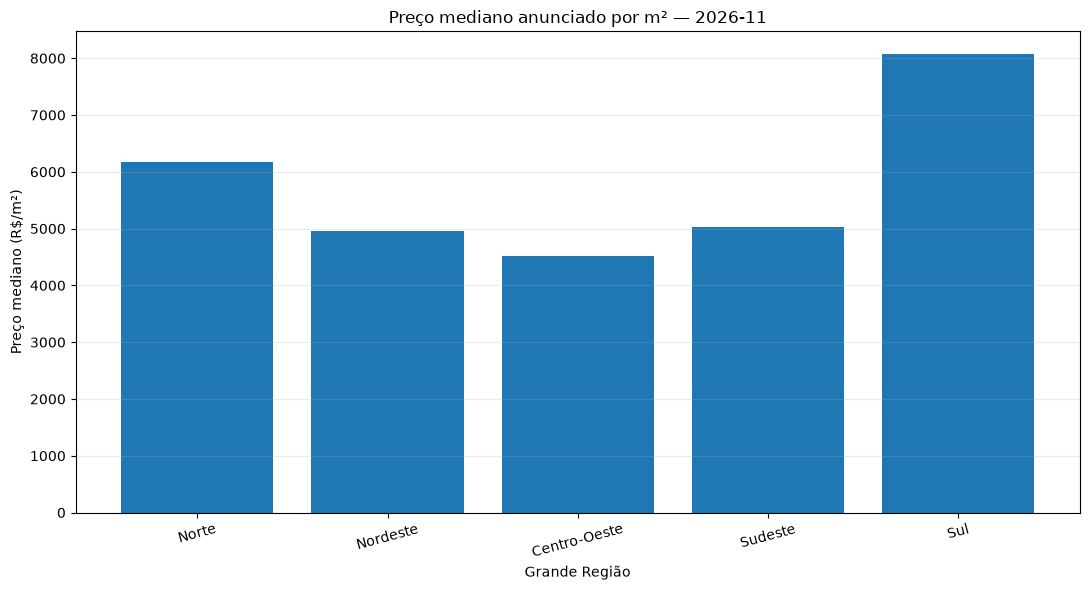

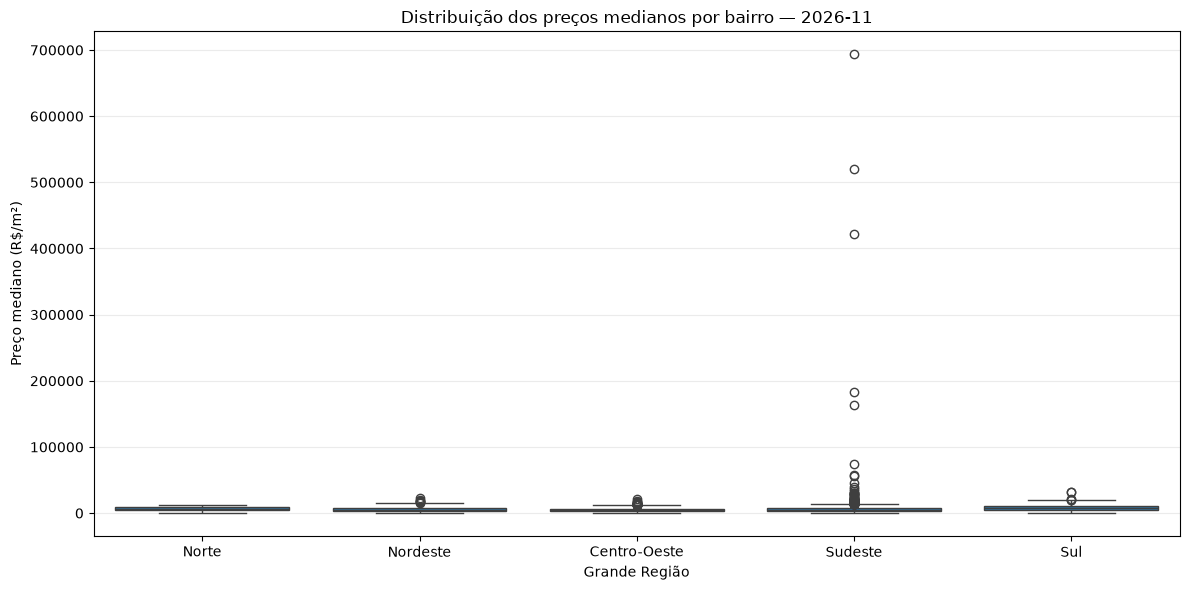

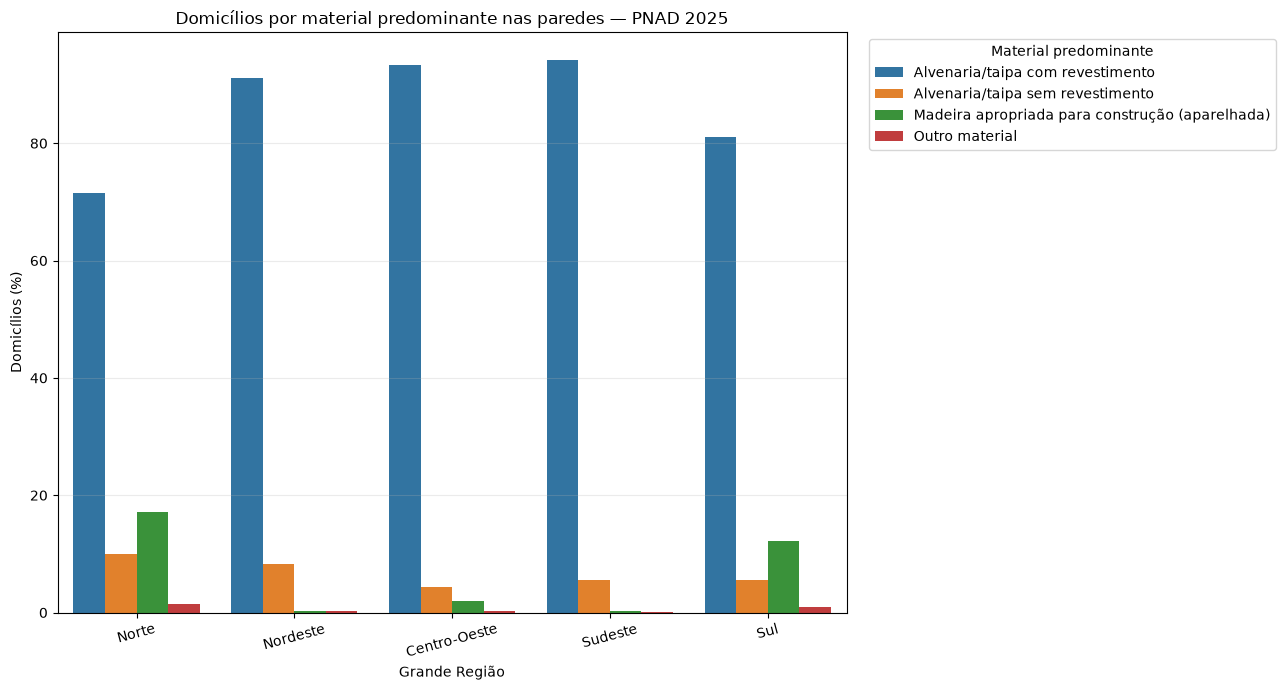

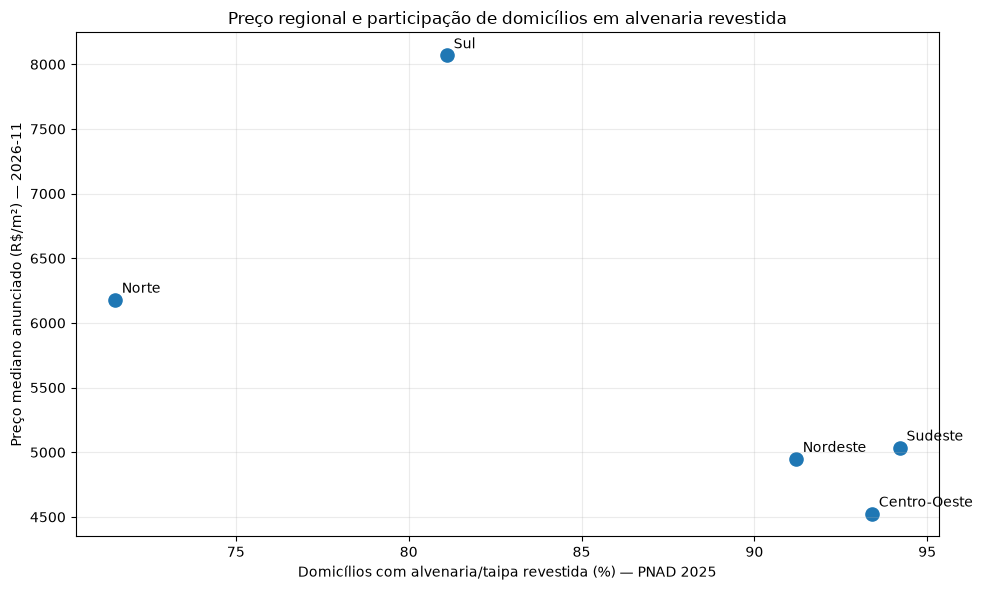

✅ Gráficos salvos na pasta: graficos


In [5]:

# ============================================================
# PARTE 5: VISUALIZAÇÃO
# ============================================================

ordem_regioes = [r for r in REGIOES if r in df_precos_regioes["regiao"].tolist()]

# 5.1 - Preço mediano por região
plt.figure(figsize=(11, 6))
dados_grafico = df_precos_regioes.set_index("regiao").reindex(ordem_regioes)
plt.bar(dados_grafico.index, dados_grafico["preco_m2_mediano_regiao"])
plt.title(f"Preço mediano anunciado por m² — {MES_REFERENCIA}")
plt.xlabel("Grande Região")
plt.ylabel("Preço mediano (R$/m²)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "01_preco_mediano_regiao.png", dpi=150)
plt.show()

# 5.2 - Distribuição dos preços por bairro
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_imoveis, x="regiao", y="mediana_m2", order=ordem_regioes)
plt.title(f"Distribuição dos preços medianos por bairro — {MES_REFERENCIA}")
plt.xlabel("Grande Região")
plt.ylabel("Preço mediano (R$/m²)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "02_boxplot_precos_bairros.png", dpi=150)
plt.show()

# 5.3 - Percentual de domicílios por material das paredes
plt.figure(figsize=(13, 7))
df_plot_pnad = df_pnad[df_pnad["regiao"].isin(ordem_regioes)]
sns.barplot(
    data=df_plot_pnad,
    x="regiao",
    y="percentual_domicilios",
    hue="material_paredes",
    order=ordem_regioes
)
plt.title("Domicílios por material predominante nas paredes — PNAD 2025")
plt.xlabel("Grande Região")
plt.ylabel("Domicílios (%)")
plt.xticks(rotation=15)
plt.legend(title="Material predominante", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(PASTA_GRAFICOS / "03_material_paredes_regiao.png", dpi=150)
plt.show()

# 5.4 - Comparação exploratória, sem inferência causal
coluna_alvenaria = "Alvenaria/taipa com revestimento"
if coluna_alvenaria in df_integrado.columns:
    plt.figure(figsize=(10, 6))
    plt.scatter(
        df_integrado[coluna_alvenaria],
        df_integrado["preco_m2_mediano_regiao"],
        s=90
    )
    for _, linha in df_integrado.iterrows():
        if pd.notna(linha[coluna_alvenaria]):
            plt.annotate(
                linha["regiao"],
                (linha[coluna_alvenaria], linha["preco_m2_mediano_regiao"]),
                xytext=(5, 5),
                textcoords="offset points"
            )
    plt.title("Preço regional e participação de domicílios em alvenaria revestida")
    plt.xlabel("Domicílios com alvenaria/taipa revestida (%) — PNAD 2025")
    plt.ylabel(f"Preço mediano anunciado (R$/m²) — {MES_REFERENCIA}")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(PASTA_GRAFICOS / "04_preco_vs_alvenaria.png", dpi=150)
    plt.show()
else:
    print("A categoria 'Alvenaria/taipa com revestimento' não foi retornada pela SIDRA.")

print("✅ Gráficos salvos na pasta:", PASTA_GRAFICOS)


In [6]:

# ============================================================
# PARTE 6: SALVAMENTO E DOCUMENTAÇÃO
# ============================================================

arquivos_saida = {
    "imoveis_bairros.csv": df_imoveis,
    "precos_cidades.csv": df_precos_cidades,
    "perfil_construtivo_pnad.csv": df_pnad,
    "integrado_regional.csv": df_integrado
}

for nome, dataframe in arquivos_saida.items():
    caminho = PASTA_DADOS / nome
    dataframe.to_csv(caminho, index=False, encoding="utf-8-sig")
    print(f"✅ Salvo: {caminho} ({caminho.stat().st_size / 1024:.1f} KB)")

tamanho_total = sum((PASTA_DADOS / nome).stat().st_size for nome in arquivos_saida)
regioes_cobertas = sorted(df_precos_regioes["regiao"].unique())
cidades_cobertas = sorted(df_precos_cidades["cidade"].unique())

metadados = {
    "data_execucao": datetime.now().isoformat(timespec="seconds"),
    "mes_referencia_precos": MES_REFERENCIA,
    "ano_referencia_pnad": 2025,
    "registros_imoveis_bairros": int(len(df_imoveis)),
    "colunas_imoveis_bairros": int(df_imoveis.shape[1]),
    "cidades": cidades_cobertas,
    "regioes": regioes_cobertas,
    "registros_pnad": int(len(df_pnad)),
    "registros_integrado": int(len(df_integrado)),
    "tamanho_csvs_bytes": int(tamanho_total)
}
with open(PASTA_DADOS / "metadados_coleta.json", "w", encoding="utf-8") as arquivo:
    json.dump(metadados, arquivo, ensure_ascii=False, indent=4)

# Documentação automática preenchida com os resultados reais da execução
tabela_resultados = df_precos_regioes.sort_values("regiao").to_string(index=False)
doc_resultados = f"""
# Resultados da coleta — Projeto Imobiliário

- **Data da execução:** {datetime.now().strftime("%d/%m/%Y %H:%M")}
- **Mês de referência dos preços:** {MES_REFERENCIA}
- **Ano de referência do perfil construtivo:** 2025
- **Registros de bairros:** {len(df_imoveis):,}
- **Colunas na base de bairros:** {df_imoveis.shape[1]}
- **Cidades contempladas:** {len(cidades_cobertas)}
- **Regiões contempladas:** {", ".join(regioes_cobertas)}
- **Registros PNAD após limpeza:** {len(df_pnad):,}
- **Registros na tabela integrada:** {len(df_integrado):,}
- **Tamanho conjunto dos CSVs:** {tamanho_total / 1024:.1f} KB

## Preço mediano regional observado

```text
{tabela_resultados}
```

## Interpretação

O preço regional é a mediana dos indicadores municipais das cidades selecionadas. A PNAD apresenta a distribuição estimada dos domicílios por material predominante nas paredes. Como as bases não identificam o material de cada imóvel anunciado, a comparação é agregada e exploratória; não permite afirmar que um material específico cause preço maior ou menor.

## Limitações desta execução

- Preços anunciados, não necessariamente valores de transação.
- Cobertura desigual de cidades entre regiões.
- Preços sem atributo individual de material construtivo.
- PNAD em nível regional e anual; preços em nível de bairro/cidade e mensal.
"""
with open("documentacao_resultados.md", "w", encoding="utf-8") as arquivo:
    arquivo.write(doc_resultados)

print("\n✅ Documentação gerada: documentacao_resultados.md")
print("\n📌 RESUMO DA EXECUÇÃO")
print(json.dumps(metadados, ensure_ascii=False, indent=2))


✅ Salvo: dados/imoveis_bairros.csv (293.1 KB)
✅ Salvo: dados/precos_cidades.csv (0.6 KB)
✅ Salvo: dados/perfil_construtivo_pnad.csv (1.0 KB)
✅ Salvo: dados/integrado_regional.csv (0.3 KB)

✅ Documentação gerada: documentacao_resultados.md

📌 RESUMO DA EXECUÇÃO
{
  "data_execucao": "2026-11-10T03:09:20",
  "mes_referencia_precos": "2026-11",
  "ano_referencia_pnad": 2025,
  "registros_imoveis_bairros": 3509,
  "colunas_imoveis_bairros": 12,
  "cidades": [
    "Belo Horizonte",
    "Belém",
    "Campinas",
    "Campo Grande",
    "Cuiabá",
    "Curitiba",
    "Florianópolis",
    "Fortaleza",
    "Goiânia",
    "João Pessoa",
    "Porto Alegre",
    "Recife",
    "Rio de Janeiro",
    "Salvador",
    "São Paulo"
  ],
  "regioes": [
    "Centro-Oeste",
    "Nordeste",
    "Norte",
    "Sudeste",
    "Sul"
  ],
  "registros_pnad": 20,
  "registros_integrado": 5,
  "tamanho_csvs_bytes": 302186
}
